In [2]:

!pip install -q imbalanced-learn joblib

from google.colab import files
uploaded = files.upload()

import pandas as pd
import numpy as np

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:")
print(df.isnull().sum())


Saving healthcare_readmission_model_v2.csv to healthcare_readmission_model_v2.csv
Dataset shape: (800, 11)


,PatientID,Age,Gender,Diagnosis,PrimaryMedication,ComorbidityCount,PriorAdmissions12M,LengthOfStayDays,DischargeDisposition,FollowUpBooked,Readmitted30Days
0,SYN-PAT-00001,49,Female,Type 2 Diabetes,Metformin,3,5,14,Home Care,Yes,No
1,SYN-PAT-00002,64,Male,COPD,Tiotropium,0,2,11,Rehabilitation,Yes,No
2,SYN-PAT-00003,70,Female,COPD,Tiotropium,3,3,1,Rehabilitation,Yes,Yes
3,SYN-PAT-00004,68,Male,Type 2 Diabetes,Metformin,5,0,7,Home,Yes,No
4,SYN-PAT-00005,61,Female,Heart Failure,Furosemide,4,0,9,Rehabilitation,No,No



Missing values:
PatientID               0
Age                     0
Gender                  0
Diagnosis               0
PrimaryMedication       0
ComorbidityCount        0
PriorAdmissions12M      0
LengthOfStayDays        0
DischargeDisposition    0
FollowUpBooked          0
Readmitted30Days        0
dtype: int64


In [3]:

# Standardize column names
df.columns = df.columns.str.strip()

target = "Readmitted30Days"
id_column = "PatientID"

# Check target labels
print(df[target].value_counts(dropna=False))

# Remove rows with missing target, if any
df = df.dropna(subset=[target]).copy()

# Convert target to binary
df[target] = (
    df[target].astype(str).str.strip().str.lower()
    .map({"yes": 1, "no": 0})
)

if df[target].isna().any():
    raise ValueError("Unexpected target labels. Check Readmitted30Days.")

# Exclude patient ID and target from predictors
X = df.drop(columns=[target, id_column], errors="ignore")
y = df[target].astype(int)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nTarget distribution:")
print(y.value_counts())


Readmitted30Days
No     580
Yes    220
Name: count, dtype: int64
Numeric features: ['Age', 'ComorbidityCount', 'PriorAdmissions12M', 'LengthOfStayDays']
Categorical features: ['Gender', 'Diagnosis', 'PrimaryMedication', 'DischargeDisposition', 'FollowUpBooked']

Target distribution:
Readmitted30Days
0    580
1    220
Name: count, dtype: int64


In [4]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 640
Testing records: 160


In [5]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

numeric_transformer = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42, k_neighbors=5)),
    ("classifier", RandomForestClassifier(
        n_estimators=500,
        max_features="sqrt",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Random Forest model training completed.")


Random Forest model training completed.


In [6]:

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "Average Precision": average_precision_score(y_test, y_prob)
}

metrics_df = pd.DataFrame(
    metrics.items(), columns=["Metric", "Score"]
)

display(metrics_df.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Not Readmitted", "Readmitted"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)


,Metric,Score
0,Accuracy,0.6938
1,Balanced Accuracy,0.5278
2,Precision,0.3684
3,Recall,0.1591
4,F1 Score,0.2222
5,ROC-AUC,0.5482
6,Average Precision,0.3265



Classification Report:
                precision    recall  f1-score   support

Not Readmitted       0.74      0.90      0.81       116
    Readmitted       0.37      0.16      0.22        44

      accuracy                           0.69       160
     macro avg       0.55      0.53      0.52       160
  weighted avg       0.64      0.69      0.65       160

Confusion Matrix:
 [[104  12]
 [ 37   7]]


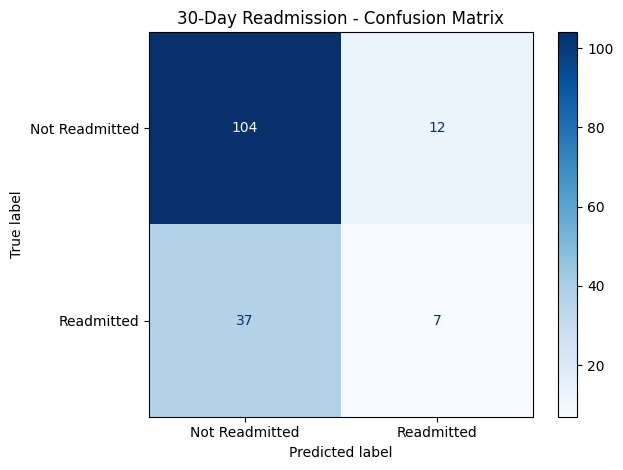

In [7]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Readmitted", "Readmitted"]
).plot(cmap="Blues", values_format="d")

plt.title("30-Day Readmission - Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()


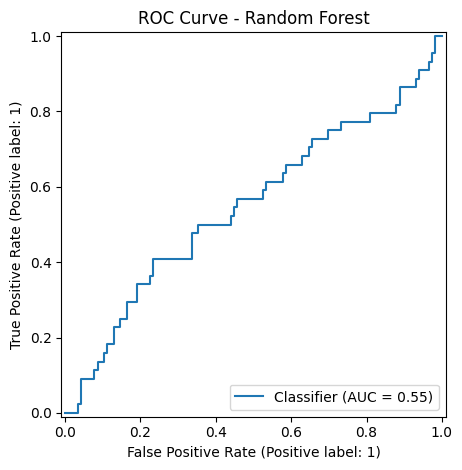

In [8]:

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve - Random Forest")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300)
plt.show()


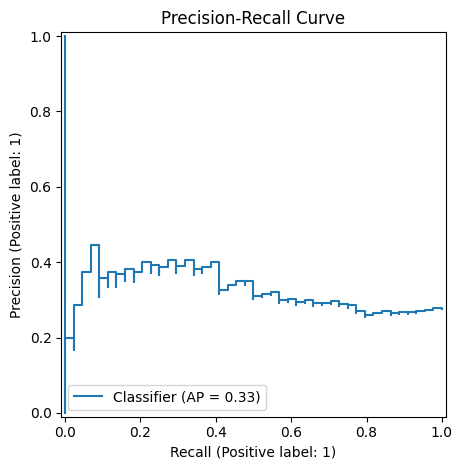

In [9]:

from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title("Precision-Recall Curve")
plt.tight_layout()
plt.savefig("precision_recall_curve.png", dpi=300)
plt.show()


,Feature,Importance,Std
5,PriorAdmissions12M,0.031994,0.025134
8,FollowUpBooked,0.015590,0.008938
0,Age,0.010050,0.020169
4,ComorbidityCount,0.008096,0.011796
7,DischargeDisposition,-0.013827,0.020738
1,Gender,-0.022803,0.026226
6,LengthOfStayDays,-0.024220,0.018895
3,PrimaryMedication,-0.028943,0.031320
2,Diagnosis,-0.033837,0.033448


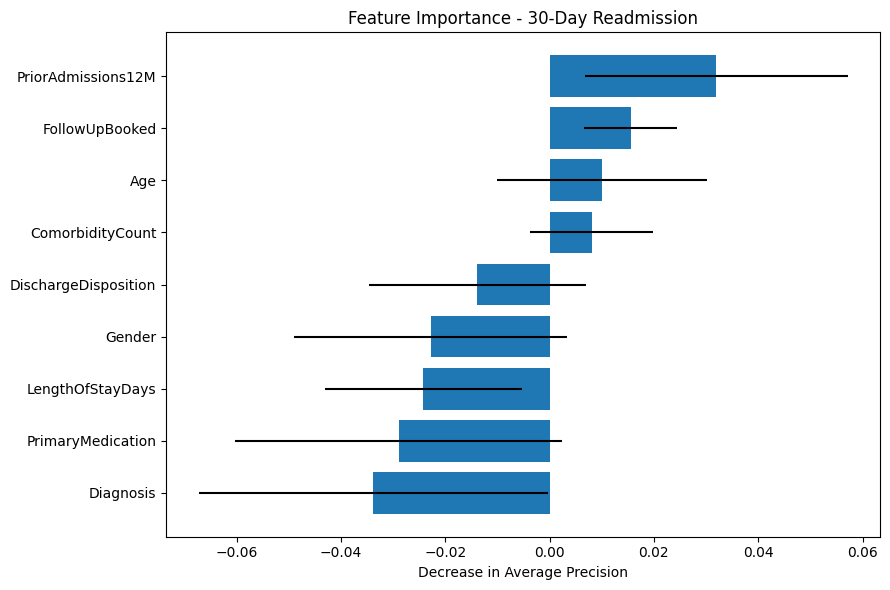

In [10]:

from sklearn.inspection import permutation_importance

importance = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="average_precision",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(9, 6))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1],
    xerr=importance_df["Std"][::-1]
)
plt.xlabel("Decrease in Average Precision")
plt.title("Feature Importance - 30-Day Readmission")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()


In [11]:

predictions = X_test.copy()

predictions["Actual_Readmission"] = y_test.values
predictions["Predicted_Readmission"] = y_pred
predictions["Readmission_Probability"] = y_prob

predictions["Actual_Readmission"] = predictions[
    "Actual_Readmission"
].map({0: "No", 1: "Yes"})

predictions["Predicted_Readmission"] = predictions[
    "Predicted_Readmission"
].map({0: "No", 1: "Yes"})

predictions.to_csv(
    "readmission_predictions.csv",
    index=False
)

print("Predictions exported successfully.")


Predictions exported successfully.


In [12]:

baseline_model = SkPipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=500,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

baseline_model.fit(X_train, y_train)

baseline_prob = baseline_model.predict_proba(X_test)[:, 1]
baseline_pred = baseline_model.predict(X_test)

comparison = pd.DataFrame([
    {
        "Model": "Random Forest + SMOTE",
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(y_test, y_prob)
    },
    {
        "Model": "Random Forest + Class Weights",
        "Recall": recall_score(y_test, baseline_pred, zero_division=0),
        "F1 Score": f1_score(y_test, baseline_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, baseline_prob),
        "Average Precision": average_precision_score(y_test, baseline_prob)
    }
])

display(comparison.round(4))
comparison.to_csv("model_comparison.csv", index=False)


,Model,Recall,F1 Score,ROC-AUC,Average Precision
0,Random Forest + SMOTE,0.1591,0.2222,0.5482,0.3265
1,Random Forest + Class Weights,0.2727,0.3333,0.5723,0.3384


In [13]:

import joblib
import json
import zipfile
import os

# Save trained model
joblib.dump(model, "readmission_random_forest_model.pkl")

# Save metrics
with open("model_metrics.json", "w") as f:
    json.dump(
        {key: float(value) for key, value in metrics.items()},
        f, indent=4
    )

# Save feature importance
importance_df.to_csv("feature_importance.csv", index=False)

# Create results ZIP
output_files = [
    "readmission_predictions.csv",
    "model_comparison.csv",
    "feature_importance.csv",
    "model_metrics.json",
    "readmission_random_forest_model.pkl",
    "confusion_matrix.png",
    "roc_curve.png",
    "precision_recall_curve.png",
    "feature_importance.png"
]

with zipfile.ZipFile(
    "Readmission_Analysis_Results.zip", "w"
) as zipf:
    for file in output_files:
        if os.path.exists(file):
            zipf.write(file)

from google.colab import files
files.download("Readmission_Analysis_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>